In [1]:
import editor

import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader

from tqdm import tqdm
import matplotlib.pyplot as plt

In [2]:
# settings
array_size = 512
num_channels = 1

nn_intake_fov = 3
nn_hidden_dim = 10

run_device = torch.device("cuda")

In [3]:
class Net(nn.Module):
    def __init__(self):
        super().__init__()
        self.fc1 = nn.Linear(nn_intake_fov * nn_intake_fov * num_channels, 24)
        self.fc2 = nn.Linear(24, 24)
        self.fc3 = nn.Linear(24, 24)
        self.fc4 = nn.Linear(24, num_channels)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        x = x.flatten(start_dim=1)

        x = F.relu(self.fc1(x))
        x = F.relu(self.fc2(x))
        x = F.relu(self.fc3(x))
        x = F.sigmoid(self.fc4(x))

        return x

In [4]:
class GameOfLifeDataset(Dataset):
    """Every possible 3x3 Game of Life neighborhood (2^9 = 512) and the center cell's next state.

    x: (1, 3, 3) float, 0 = dead, 1 = alive
    y: (1,)      float, next state of the center cell
    """

    def __init__(self):
        codes = torch.arange(512, device=run_device)
        bits = (codes[:, None] >> torch.arange(9, device=run_device)) & 1          # (512, 9)
        self.x = bits.float().reshape(512, 1, 3, 3)

        center = self.x[:, 0, 1, 1]
        neighbors = self.x.sum(dim=(1, 2, 3)) - center
        alive = (neighbors == 3) | ((center == 1) & (neighbors == 2))
        self.y = alive.float()[:, None]

    def __len__(self):
        return len(self.x)

    def __getitem__(self, i):
        return self.x[i], self.y[i]

In [5]:
model = Net().to(run_device)

In [6]:
loss_fn = nn.MSELoss()
optim = optim.AdamW(model.parameters(), lr=0.001)

In [7]:
dset = GameOfLifeDataset()
dloader = DataLoader(dset, batch_size=1024, shuffle=True)

In [8]:
loss_list = []

for epoch in tqdm(range(1000)):
    for batch in dloader:
        optim.zero_grad()
        out = model(batch[0])
        loss = loss_fn(out, batch[1])
        loss.backward()
        optim.step()
        
        # loggin
        loss_list.append(loss.item())

100%|██████████| 1000/1000 [00:04<00:00, 209.38it/s]


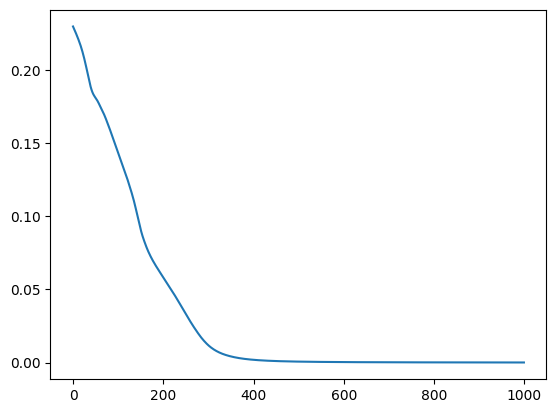

In [9]:
plt.plot(loss_list)

In [10]:
class TempSim:
    def __init__(self, model):
        self.model = model
        
    def extract_kernel(self, global_tensor: torch.tensor, start_x, end_x, start_y, end_y):
        return global_tensor[:, start_x:end_x, start_y:end_y]
    
    def step(self, state: torch.tensor):
        state = state.to(run_device)
        
        C, H, W = state.shape
        k = nn_intake_fov
        lo, hi = (k - 1) // 2, k // 2
        x = F.pad(state[None], (lo, hi, lo, hi), mode="circular")
        slices = F.unfold(x, k).transpose(1, 2).reshape(H * W, C, k, k)  # one slice per cell
        out = self.model(slices)                                         # (H*W, outputs per slice)
        
        out = out.cpu()
        
        return out.reshape(H, W, -1).permute(2, 0, 1)                    # (outputs per slice, H, W)

In [11]:
sim = TempSim(model)

In [12]:
editor = editor.NCAEditor(sim, torch.rand((num_channels, array_size, array_size)))

In [13]:
editor.run()

In [14]:
def extract_kernel(global_tensor: torch.tensor, start_x, end_x, start_y, end_y):
    return global_tensor[:, start_x:end_x, start_y:end_y]

In [15]:
startx = 0
starty = 0

endx = 2
endy = 2

In [16]:
x = torch.tensor(((1, 2, 3, 4),
                  (5, 6, 7, 8),
                  (9, 0, 1, 2),
                  (3, 4, 5, 6))).unsqueeze(0)

In [17]:
extract_kernel(x, 1, 4, 1, 4)

tensor([[[6, 7, 8],
         [0, 1, 2],
         [4, 5, 6]]])